In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
from PIL import Image
import io
from scipy.spatial import ConvexHull

# go to above directory
import os
os.chdir('..')

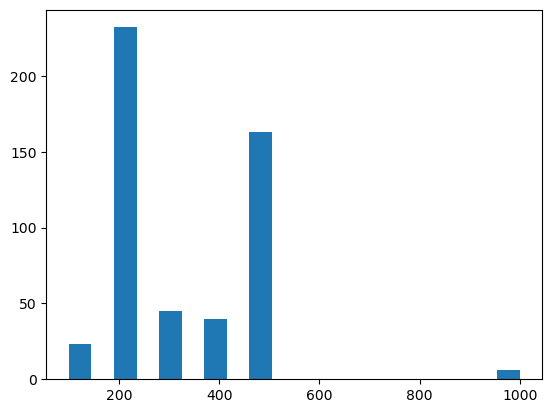

In [2]:
# boxes where constellations are found
constellation_slices_filenames = glob.glob('web-images/*.png')
length_of_boxes = np.asarray([float(f.split('_')[-1].strip('.png')) for f in constellation_slices_filenames])
plt.hist(length_of_boxes, bins=20);

In [3]:
# getting images from firebase
import firebase_admin
from firebase_admin import credentials, storage, firestore

# Download a service account key from Firebase console:
# Project Settings → Service accounts → Generate new private key
cred = credentials.Certificate('stats/firebase-key.json')
firebase_admin.initialize_app(cred, {
    'storageBucket': 'galactic-constellations.firebasestorage.app'
})

db = firestore.client()
bucket = storage.bucket()

# List all submitted images
blobs = list(bucket.list_blobs(prefix='generated-constellations/'))
print(f'{len(blobs)} images')

48 images


In [4]:
from scipy import ndimage

In [8]:
c_size = []
box_size = []
MIN_COMPONENT = 50  # pixels
for blob in bucket.list_blobs(prefix='generated-constellations/'):
    if not blob.name.endswith('.png'):
        continue
    try:
        data = blob.download_as_bytes()
        img = np.array(Image.open(io.BytesIO(data)).convert('RGB'))
    except:
        continue
    
    # HSV conversion
    imgf = img.astype(float) / 255.0
    r, g, b = imgf[:,:,0], imgf[:,:,1], imgf[:,:,2]
    maxc = np.maximum(r, np.maximum(g, b))
    minc = np.minimum(r, np.minimum(g, b))
    v = maxc
    s = np.where(maxc > 0, (maxc - minc) / maxc, 0)
    diff = maxc - minc
    h = np.zeros_like(v)
    mr = (maxc == r) & (diff > 0)
    mg = (maxc == g) & (diff > 0)
    mb = (maxc == b) & (diff > 0)
    h[mr] = ((g[mr] - b[mr]) / diff[mr]) % 6
    h[mg] = ((b[mg] - r[mg]) / diff[mg]) + 2
    h[mb] = ((r[mb] - g[mb]) / diff[mb]) + 4
    h = h / 6.0

    # Teal mask
    teal = (h > 0.4) & (h < 0.55) & (s > 0.3) & (v > 0.3)

    # Keep only large connected components
    labeled, n = ndimage.label(teal)
    sizes = ndimage.sum(teal, labeled, range(1, n + 1))
    big = [i + 1 for i, sz in enumerate(sizes) if sz >= MIN_COMPONENT]
    clean = np.isin(labeled, big)

    if clean.sum() < 3:
        continue

    points = np.argwhere(clean)
    
    hull = ConvexHull(points)
    hull_pts = points[hull.vertices]
    
    # Max distance between any two hull vertices
    from scipy.spatial.distance import pdist
    max_dist_px = pdist(hull_pts).max()
    
    # As fraction of image diagonal
    side_length = img.shape[0]
    max_dist_frac = max_dist_px / side_length
    
    name = blob.name.split('/')[-1]
    image_size = float(name.split('size_')[-1].split('_')[0])
    c_size.append(image_size*max_dist_frac)
    box_size.append(np.sqrt(2)*image_size)
    #print(name, max_dist_frac.round(2), image_size)

C:\Users\cmlam\AppData\Local\Temp\ipykernel_19108\3833356453.py:19: RuntimeWarning: invalid value encountered in divide
  s = np.where(maxc > 0, (maxc - minc) / maxc, 0)


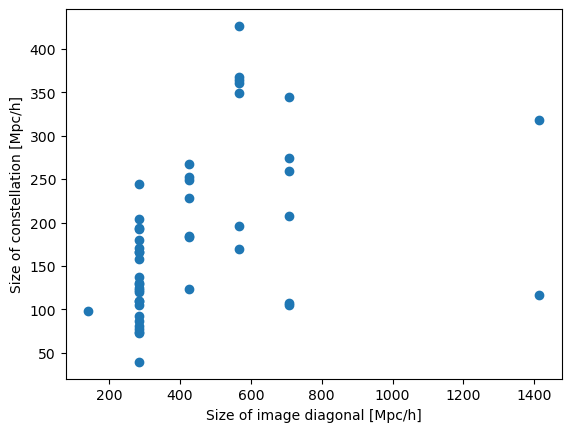

In [9]:
plt.scatter(box_size, c_size);
plt.xlabel('Size of image diagonal [Mpc/h]')
plt.ylabel('Size of constellation [Mpc/h]');

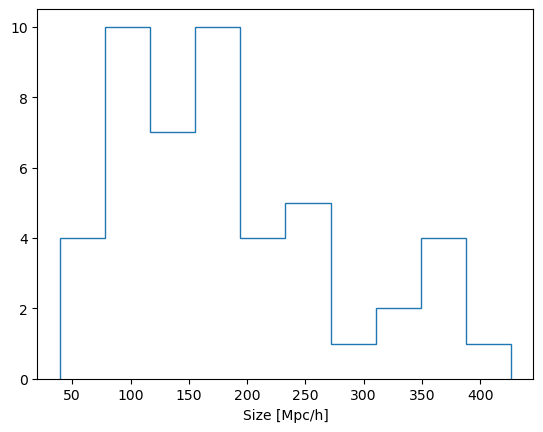

In [10]:
plt.hist(c_size, bins=10, histtype='step', label='Constellation Size');
#plt.hist(box_size, bins=20, histtype='step', label='Box_Size');

plt.xlabel('Size [Mpc/h]');